In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

### Load the patient data

In [2]:
# Load patient metadata
df = pd.read_parquet("../metadata/patient_metadata.parquet")
df

,TCGA Participant Barcode,TCGA Project Code,Organ,Pathologic T,Pathologic N,Pathologic M,Pathologic Stage,Country,Gender,Age at initial pathologic diagnosis,...,SBS13,SBS15,SBS17a,SBS17b,SBS18,SBS20,SBS21,SBS28,SBS29,SBS40a
0,TCGA-2H-A9GF,ESCA,Esophageal,T3,N1,M0,III,Netherlands,MALE,67.04,...,0,0,1,1,0,0,0,0,0,0
1,TCGA-2H-A9GH,ESCA,Esophageal,T1,N1,M0,IIB,Netherlands,MALE,44.35,...,0,0,1,1,0,0,0,0,0,0
2,TCGA-2H-A9GI,ESCA,Esophageal,T3,N1,M0,III,Netherlands,MALE,68.71,...,0,0,1,1,0,0,0,0,0,1
3,TCGA-2H-A9GK,ESCA,Esophageal,T3,N1,M0,III,Netherlands,MALE,43.99,...,1,0,1,1,0,0,0,0,0,0
4,TCGA-2H-A9GL,ESCA,Esophageal,T3,N1,M0,III,Netherlands,MALE,74.24,...,0,0,1,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
916,TCGA-WS-AB45,COAD,COAD,T3,N0,MX,IIA,United_States,FEMALE,52.00,...,0,0,0,0,0,0,0,0,0,0
917,TCGA-X8-AAAR,ESCA,Esophageal,T1,N1,None,None,United_States,MALE,69.46,...,0,1,1,1,0,0,0,0,0,0
918,TCGA-ZA-A8F6,STAD,Gastric,T2,N0,MX,IB,United_States,MALE,71.52,...,0,0,0,0,0,0,0,0,0,0
919,TCGA-ZQ-A9CR,STAD,Gastric,T4a,N3,MX,IIIC,United_Kingdom,FEMALE,79.69,...,0,1,0,1,0,0,0,0,0,0


### Perform the stratified train-val split

In [24]:
# Perform the stratified train test split
cols_for_strat = [
    # "TCGA Project Code",
    # "Organ",
    # "Stage",
    # "Gender",
    # "Vital status",
    # "Anatomic Region",
    "MSI Status",
]

X_train, X_val = train_test_split(df, test_size=0.2, random_state=1, stratify=df[cols_for_strat])

In [25]:
# Choose columns of interest
cols_of_interest = [
    "TCGA Project Code",
    "Organ",
    "Stage",
    "Gender",
    "Vital status",
    "Anatomic Region",
    "MSI Status",
]
sig_cols = [col for col in df.columns if col.startswith("SBS")]
cols_of_interest += sig_cols

### Check and plot the class distributions between datasets

In [26]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [27]:
# Count train classes
count_cols = []

for col in cols_of_interest:
    count_col = X_train[col].value_counts().sort_index().reset_index(drop=True).to_frame(name=col)
    count_cols.append(count_col)

class_count_df = pd.concat(count_cols, axis=1)
class_percentages_df = class_count_df / class_count_df.sum(axis=0)

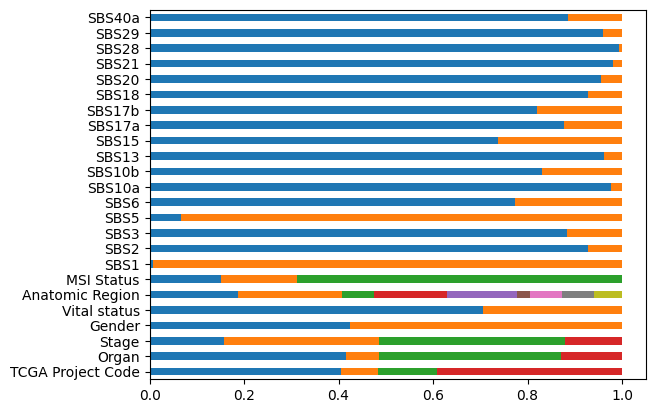

In [28]:
class_percentages_df.T.plot(
    kind="barh",
    stacked=True
)
plt.legend().set_visible(False)

In [29]:
# Count val classes
count_cols = []

for col in cols_of_interest:
    count_col = X_val[col].value_counts().sort_index().reset_index(drop=True).to_frame(name=col)
    count_cols.append(count_col)

class_count_df = pd.concat(count_cols, axis=1)
class_percentages_df = class_count_df / class_count_df.sum(axis=0)

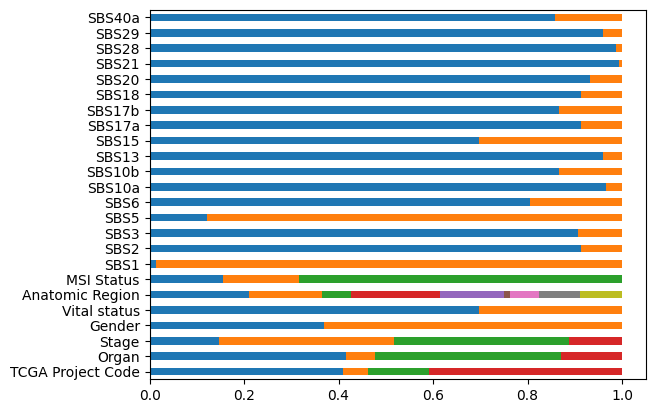

In [30]:
class_percentages_df.T.plot(
    kind="barh",
    stacked=True
)
plt.legend().set_visible(False)

### Save the dataset split

In [16]:
# Save datasets as separate parquet files
X_train.to_parquet("data/patient_metadata_train.parquet")
X_val.to_parquet("data/patient_metadata_val.parquet")